In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import sqlite3 

In [2]:
df = pd.read_csv(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Customer Churn Analysis\data\telco.csv")

df['Total Charges']= pd.to_numeric(df['Total Charges'], errors='coerce')
df.dropna(subset=['Total Charges'], inplace=True)

df['churn_binary'] =(df['Churn Label'] == 'Yes').astype(int)

print(f'Dataset shape: {df.shape}')
print(f'Churn rate: {df["churn_binary"].mean() * 100:.1f}%')
print(df.dtypes)

Dataset shape: (7043, 51)
Churn rate: 26.5%
Customer ID                           object
Gender                                object
Age                                    int64
Under 30                              object
Senior Citizen                        object
Married                               object
Dependents                            object
Number of Dependents                   int64
Country                               object
State                                 object
City                                  object
Zip Code                               int64
Latitude                             float64
Longitude                            float64
Population                             int64
Quarter                               object
Referred a Friend                     object
Number of Referrals                    int64
Tenure in Months                       int64
Offer                                 object
Phone Service                         object
Avg Monthly

### Q1 - What is the overall churn rate?

Churn rate: 26.5%


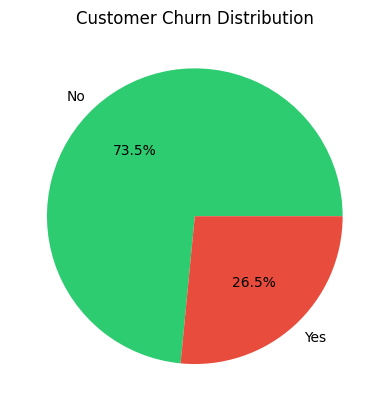

In [3]:
churn_rate = df['churn_binary'].mean() * 100
print(f'Churn rate: {churn_rate:.1f}%')

df['Churn Label'].value_counts().plot(kind ='pie', autopct='%1.1f%%',colors=['#2ecc71','#e74c3c'])
plt.title('Customer Churn Distribution')
plt.ylabel('')
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Customer Churn Analysis\visuals\churn_distribution.png" , bbox_inches='tight')
plt.show()

### Q2 - Which contract type has the highest churn?

C:\Users\Pushk\AppData\Local\Temp\ipykernel_69180\2247586012.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=contract_churn, x='Contract' , y='churn_rate', palette='Reds_d')


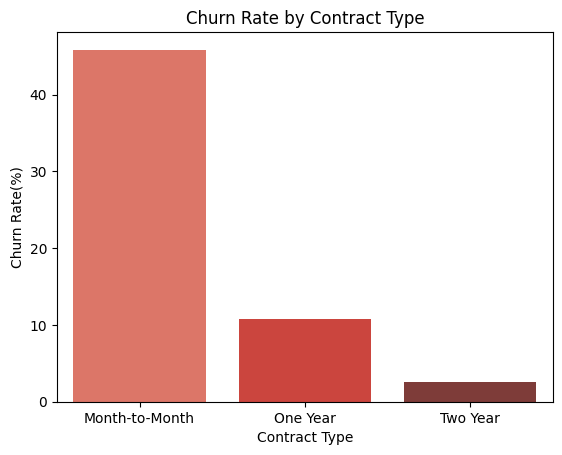

In [4]:
contract_churn = df.groupby('Contract')['churn_binary'].mean().reset_index()
contract_churn.columns = ['Contract', 'churn_rate']
contract_churn['churn_rate'] = contract_churn['churn_rate'] * 100

sns.barplot(data=contract_churn, x='Contract' , y='churn_rate', palette='Reds_d')
plt.title('Churn Rate by Contract Type')
plt.ylabel('Churn Rate(%)')
plt.xlabel('Contract Type')
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Customer Churn Analysis\visuals\churn_by_contract.png" , bbox_inches='tight')
plt.show()

### Q3 - How does tenure affect churn?

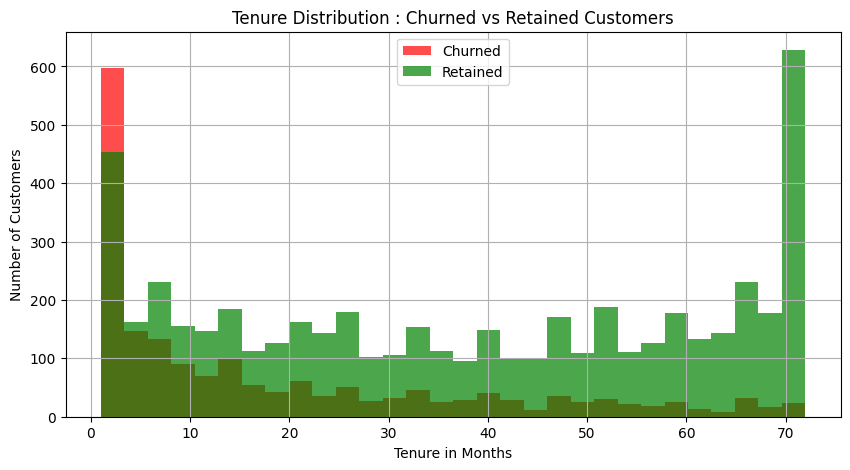

In [5]:
fig , ax = plt.subplots(figsize=(10,5))
df[df['Churn Label']=='Yes']['Tenure in Months'].hist(ax=ax,bins=30,alpha=0.7,color='red',label='Churned')
df[df['Churn Label']=='No']['Tenure in Months'].hist(ax=ax,bins=30,alpha=0.7,color='green',label='Retained')

plt.title('Tenure Distribution : Churned vs Retained Customers')
plt.xlabel('Tenure in Months')
plt.ylabel('Number of Customers')
plt.legend()
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Customer Churn Analysis\visuals\tenure_vs_churn.png", bbox_inches='tight')
plt.show()

### Q4 - Do higher monthly charges lead to more churn?

C:\Users\Pushk\AppData\Local\Temp\ipykernel_69180\3995624263.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn Label', y='Monthly Charge', palette={'No': '#2ecc71', 'Yes': '#e74c3c'})


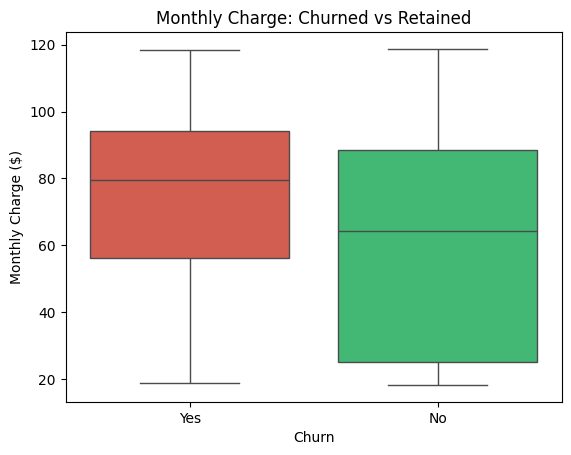

In [7]:
sns.boxplot(data=df, x='Churn Label', y='Monthly Charge', palette={'No': '#2ecc71', 'Yes': '#e74c3c'})
plt.title('Monthly Charge: Churned vs Retained')
plt.xlabel('Churn')
plt.ylabel('Monthly Charge ($)')
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Customer Churn Analysis\visuals\monthly_charge_vs_churn.png", bbox_inches='tight')
plt.show()

### Q5 - Which internet service type churns most?

C:\Users\Pushk\AppData\Local\Temp\ipykernel_69180\4162644279.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=internet_churn, x='Internet Type', y='churn_rate', palette='Blues_d')


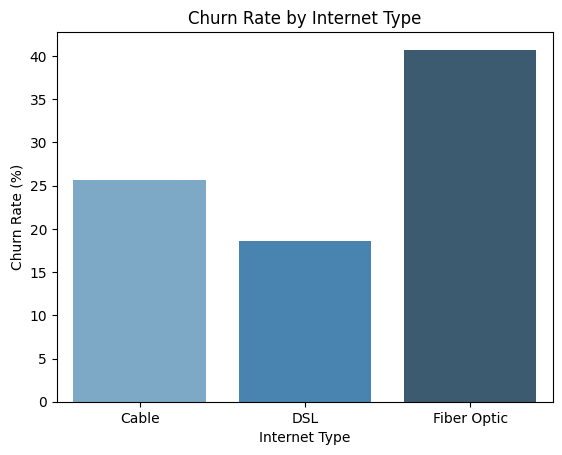

In [8]:
internet_churn = df.groupby('Internet Type')['churn_binary'].mean().reset_index()
internet_churn['churn_rate'] = internet_churn['churn_binary'] * 100

sns.barplot(data=internet_churn, x='Internet Type', y='churn_rate', palette='Blues_d')
plt.title('Churn Rate by Internet Type')
plt.ylabel('Churn Rate (%)')
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Customer Churn Analysis\visuals\churn_by_internet_type.png", bbox_inches='tight')
plt.show()

### Q6 - Does tech support reduce churn?


C:\Users\Pushk\AppData\Local\Temp\ipykernel_69180\3939170761.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tech_churn, x='Premium Tech Support', y='churn_rate', palette='Purples_d')


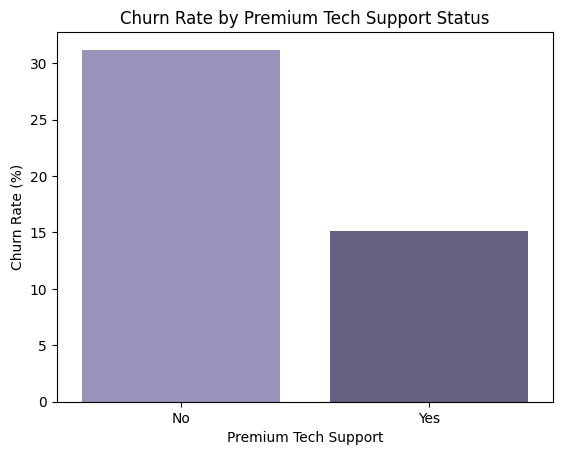

In [10]:
tech_churn = df.groupby('Premium Tech Support')['churn_binary'].mean().reset_index()
tech_churn['churn_rate'] = tech_churn['churn_binary'] * 100

sns.barplot(data=tech_churn, x='Premium Tech Support', y='churn_rate', palette='Purples_d')
plt.title('Churn Rate by Premium Tech Support Status')
plt.ylabel('Churn Rate (%)')
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Customer Churn Analysis\visuals\churn_by_tech_support.png", bbox_inches='tight')
plt.show()

### Q7 - Which payment method has the most churners?

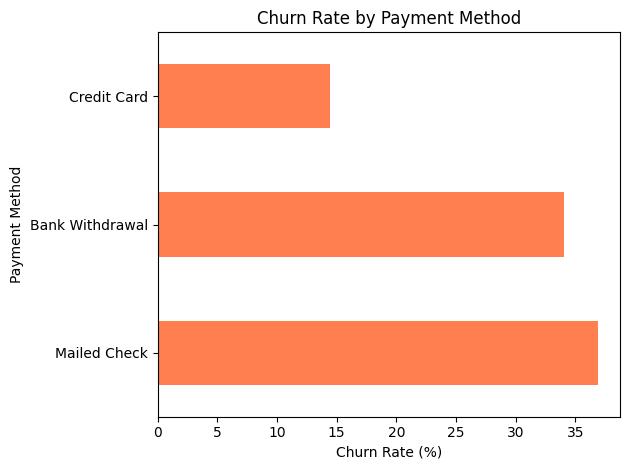

In [11]:
pay_churn = df.groupby('Payment Method')['churn_binary'].mean().sort_values(ascending=False) * 100

pay_churn.plot(kind='barh', color='coral')
plt.title('Churn Rate by Payment Method')
plt.xlabel('Churn Rate (%)')
plt.tight_layout()
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Customer Churn Analysis\visuals\churn_by_payment.png", bbox_inches='tight')
plt.show()

### Q8 - Correlation heatmap of numeric features

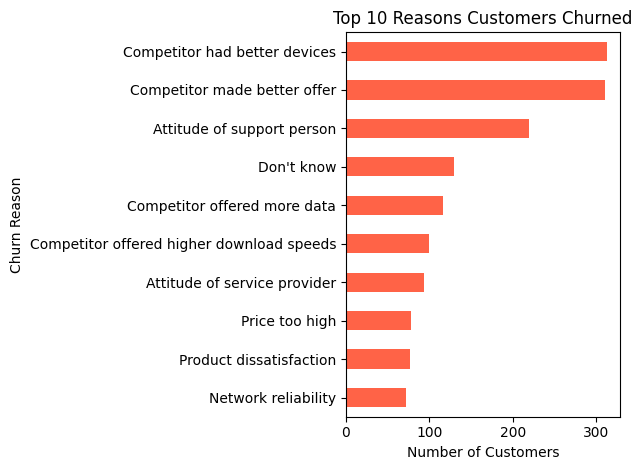

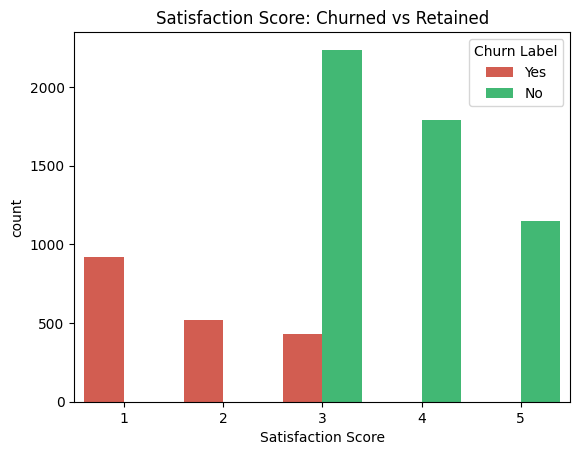

In [12]:
churn_reasons = df[df['Churn Label'] == 'Yes']['Churn Reason'].value_counts().head(10)

churn_reasons.plot(kind='barh', color='tomato')
plt.title('Top 10 Reasons Customers Churned')
plt.xlabel('Number of Customers')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Customer Churn Analysis\visuals\top_churn_reasons.png", bbox_inches='tight')
plt.show()

# Also: Satisfaction Score distribution for churned vs retained
sns.countplot(data=df, x='Satisfaction Score', hue='Churn Label',
              palette={'No': '#2ecc71', 'Yes': '#e74c3c'})
plt.title('Satisfaction Score: Churned vs Retained')
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Customer Churn Analysis\visuals\satisfaction_vs_churn.png", bbox_inches='tight')
plt.show()